# 06 · CineMongo: um catálogo no estilo dos streamings

**Pré-requisito:** notebooks 00 a 05.

No notebook 05, cada face virou um arquivo no GridFS com metadados, e o app mostrava uma galeria. Aqui fazemos a mesma coisa, só que melhor: cada item é um **título** (série de TV), com **pôster**, **nota**, **ano**, **gêneros** e **sinopse**. No final, um app no estilo dos serviços de streaming:

- uma **busca por título**;
- um **destaque** no topo;
- **fileiras por categoria**: para o lado você vê mais títulos, para baixo vê outras categorias;
- uma **página de detalhes** ao clicar num pôster.

Este notebook é um **passo a passo completo**: todas as células já estão preenchidas. Rode uma por vez e observe o resultado. No final fica o **Exercício 10**.

| Notebook 05 (faces) | Notebook 06 (títulos) |
|---|---|
| foto da face no GridFS | pôster no GridFS |
| metadados: pessoa, expressão | documento com título, gêneros, nota, ano, sinopse |
| galeria em grade | fileiras por categoria + busca + detalhes |

> **De onde vêm os dados:** da API pública do **TVmaze** (https://www.tvmaze.com/api), gratuita e **sem chave de acesso**. Os dados são licenciados como **CC BY-SA**: por isso o app mostra no rodapé que vieram do TVmaze.

In [1]:
#%pip install -q pymongo python-dotenv pillow numpy matplotlib requests streamlit

---
## Conexão

A célula conecta ao MongoDB e **apaga o banco `catalogo_db`** antes de começar, para você poder rodar o notebook de novo sem acumular dados repetidos.

In [2]:
import os, io, re, html, requests, gridfs
from dotenv import load_dotenv
from pymongo import MongoClient
from PIL import Image
from IPython.display import display

load_dotenv()
client = MongoClient(os.environ["MONGO_URI"])
client.admin.command("ping")

client.drop_database("catalogo_db")       # começa do zero
db = client["catalogo_db"]
fs = gridfs.GridFS(db)
print("Conectado. Banco catalogo_db pronto (vazio).")

Conectado. Banco catalogo_db pronto (vazio).


---
## Parte 1 · Conhecendo a API

Uma API é um **garçom**: você faz o pedido por um endereço (URL) e ela traz a resposta em **JSON**. O endereço abaixo devolve uma página com cerca de 250 séries:

```
https://api.tvmaze.com/shows?page=0
```

O `requests.get` faz o pedido e o `.json()` transforma a resposta em lista de dicionários do Python.

In [3]:
resposta = requests.get("https://api.tvmaze.com/shows?page=0", timeout=30)
resposta.raise_for_status()               # para aqui se a API respondeu com erro
shows = resposta.json()

print(len(shows), "títulos recebidos")

240 títulos recebidos


Veja como chega **um** título. Repare que alguns campos são objetos dentro do objeto (`rating`, `image`, `network`) e que a sinopse (`summary`) vem com marcações HTML, como `<p>` e `<b>`:

In [4]:
exemplo = shows[0]
for campo in ["id", "name", "genres", "language", "premiered", "status", "rating", "network", "image", "summary"]:
    print(f"{campo:10} -> {exemplo.get(campo)}")

id         -> 1
name       -> Under the Dome
genres     -> ['Drama', 'Science-Fiction', 'Thriller']
language   -> English
premiered  -> 2013-06-24
status     -> Ended
rating     -> {'average': 6.6}
network    -> {'id': 2, 'name': 'CBS', 'country': {'name': 'United States', 'code': 'US', 'timezone': 'America/New_York'}, 'officialSite': 'https://www.cbs.com/'}
image      -> {'medium': 'https://static.tvmaze.com/uploads/images/medium_portrait/610/1525272.jpg', 'original': 'https://static.tvmaze.com/uploads/images/original_untouched/610/1525272.jpg'}
summary    -> <p><b>Under the Dome</b> is the story of a small town that is suddenly and inexplicably sealed off from the rest of the world by an enormous transparent dome. The town's inhabitants must deal with surviving the post-apocalyptic conditions while searching for answers about the dome, where it came from and if and when it will go away.</p>


---
## Parte 2 · Do JSON da API para os nossos documentos

A API traz muito mais do que precisamos, e num formato que não é o ideal. Vamos montar **o nosso documento**, com nomes em português e só o que o app usa:

| Campo nosso | Vem de | Tratamento |
|---|---|---|
| `tvmaze_id` | `id` | — |
| `titulo` | `name` | — |
| `generos` | `genres` | traduzidos para português |
| `nota` | `rating.average` | pode não existir (`None`) |
| `ano` | `premiered` | só os 4 primeiros caracteres, como número |
| `idioma`, `status`, `emissora` | `language`, `status`, `network.name` | `emissora` pode não existir |
| `peso` | `weight` | popularidade no TVmaze, usada na fileira “Em alta” |
| `sinopse` | `summary` | sem as marcações HTML |
| `url_poster` | `image.medium` | usado na Parte 3 para baixar o pôster |

Títulos **sem pôster** ou **sem gênero** ficam de fora: eles não teriam como aparecer nas fileiras.

In [5]:
GENEROS_PT = {
    "Drama": "Drama", "Comedy": "Comédia", "Action": "Ação", "Crime": "Crime",
    "Thriller": "Suspense", "Science-Fiction": "Ficção científica", "Horror": "Terror",
    "Romance": "Romance", "Adventure": "Aventura", "Fantasy": "Fantasia", "Mystery": "Mistério",
    "Family": "Família", "Medical": "Médico", "Legal": "Jurídico", "Supernatural": "Sobrenatural",
    "History": "História", "War": "Guerra", "Music": "Música", "Western": "Faroeste",
    "Anime": "Anime", "Sports": "Esportes", "Children": "Infantil", "Espionage": "Espionagem",
    "Food": "Culinária", "Travel": "Viagem", "Nature": "Natureza", "DIY": "Faça você mesmo",
}

titulos = []
for s in shows:
    if not s.get("image") or not s.get("genres"):
        continue

    sinopse = re.sub(r"<[^>]+>", "", s.get("summary") or "")    # tira as marcações <p>, <b>...
    sinopse = html.unescape(sinopse).strip()                      # &amp; vira &

    titulos.append({
        "tvmaze_id": s["id"],
        "titulo": s["name"],
        "generos": [GENEROS_PT.get(g, g) for g in s["genres"]],
        "nota": (s.get("rating") or {}).get("average"),
        "ano": int(s["premiered"][:4]) if s.get("premiered") else None,
        "idioma": s.get("language"),
        "status": s.get("status"),
        "emissora": (s.get("network") or {}).get("name"),
        "peso": s.get("weight", 0),
        "sinopse": sinopse,
        "url_poster": s["image"]["medium"],
    })

print(len(titulos), "títulos prontos de", len(shows))
print(titulos[0])

235 títulos prontos de 240
{'tvmaze_id': 1, 'titulo': 'Under the Dome', 'generos': ['Drama', 'Ficção científica', 'Suspense'], 'nota': 6.6, 'ano': 2013, 'idioma': 'English', 'status': 'Ended', 'emissora': 'CBS', 'peso': 100, 'sinopse': "Under the Dome is the story of a small town that is suddenly and inexplicably sealed off from the rest of the world by an enormous transparent dome. The town's inhabitants must deal with surviving the post-apocalyptic conditions while searching for answers about the dome, where it came from and if and when it will go away.", 'url_poster': 'https://static.tvmaze.com/uploads/images/medium_portrait/610/1525272.jpg'}


Agora gravamos tudo de uma vez na coleção `titulos`:

In [6]:
db.titulos.insert_many(titulos)
print(db.titulos.count_documents({}), "documentos em catalogo_db.titulos")

235 documentos em catalogo_db.titulos


### Índices: o sumário do livro

Sem índice, para achar os títulos de “Drama” o MongoDB lê **todos** os documentos, um por um. Um **índice** é como o sumário de um livro: uma lista ordenada que aponta direto para onde está cada valor. O app vai filtrar muito por gênero e ordenar por nota, então criamos índices nesses campos. O `unique=True` ainda impede dois documentos com o mesmo `tvmaze_id`.

In [7]:
db.titulos.create_index("tvmaze_id", unique=True)
db.titulos.create_index("generos")
db.titulos.create_index([("nota", -1)])

for nome in db.titulos.index_information():
    print(nome)

_id_
tvmaze_id_1
generos_1
nota_-1


---
## Parte 3 · Os pôsteres no GridFS

Igual às faces do notebook 04: cada pôster vai para o GridFS. A diferença é que agora o documento do título **guarda o `_id` do pôster** (`poster_id`). É uma **referência**: o título aponta para o arquivo, como uma etiqueta “ver caixa 12”.

```
titulos  { titulo: "...", generos: [...], poster_id: ObjectId("…") }
                                              │
fs.files { _id: ObjectId("…"), filename: "169.jpg" }  ──▶  fs.chunks
```

São cerca de 250 imagens pequenas: leva **um ou dois minutos**. O `requests.Session()` reaproveita a mesma conexão para todos os downloads, o que deixa tudo mais rápido.

In [8]:
sessao = requests.Session()
gravados = 0
falhas = 0

for t in list(db.titulos.find({}, {"tvmaze_id": 1, "titulo": 1, "url_poster": 1})):
    try:
        r = sessao.get(t["url_poster"], timeout=30)
        r.raise_for_status()
    except Exception:
        falhas += 1
        continue

    poster_id = fs.put(r.content, filename=f"{t['tvmaze_id']}.jpg",
                       metadata={"tvmaze_id": t["tvmaze_id"], "titulo": t["titulo"]})
    db.titulos.update_one({"_id": t["_id"]}, {"$set": {"poster_id": poster_id}})

    gravados += 1
    if gravados % 50 == 0:
        print(gravados, "pôsteres gravados...")

print(f"Pronto: {gravados} pôsteres no GridFS, {falhas} falha(s)")

50 pôsteres gravados...
100 pôsteres gravados...
150 pôsteres gravados...
200 pôsteres gravados...
Pronto: 235 pôsteres no GridFS, 0 falha(s)


### Cada título com o seu pôster e a sua descrição

Para mostrar um título, buscamos o documento e, pelo `poster_id`, o arquivo no GridFS. Os três títulos de nota mais alta:

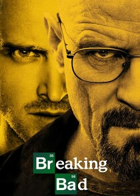

Breaking Bad (2008) ★ 9.2
Gêneros: Drama, Crime, Suspense
Breaking Bad follows protagonist Walter White, a chemistry teacher who lives in New Mexico with his wife and teenage son who has cerebral palsy. White is diagnosed with Stage III cancer and given a prognosis of two years left to live. With a new sens ...
----------------------------------------------------------------------


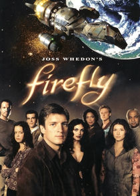

Firefly (2002) ★ 9
Gêneros: Drama, Aventura, Ficção científica
Five hundred years in the future, a renegade crew aboard a small spacecraft tries to survive as they travel the unknown parts of the galaxy and evade warring factions as well as authority agents out to get them. ...
----------------------------------------------------------------------


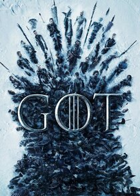

Game of Thrones (2011) ★ 8.9
Gêneros: Drama, Aventura, Fantasia
Based on the bestselling book series A Song of Ice and Fire by George R.R. Martin, this sprawling new HBO drama is set in a world where summers span decades and winters can last a lifetime. From the scheming south and the savage eastern lands, to the ...
----------------------------------------------------------------------


In [9]:
for t in db.titulos.find({"nota": {"$ne": None}}).sort("nota", -1).limit(3):
    if t.get("poster_id"):
        display(Image.open(io.BytesIO(fs.get(t["poster_id"]).read())).resize((140, 196)))
    print(t["titulo"], f"({t['ano']})", "★", t["nota"])
    print("Gêneros:", ", ".join(t["generos"]))
    print(t["sinopse"][:250], "...")
    print("-" * 70)

---
## Parte 4 · As consultas por trás da página

Antes de montar o app, veja cada consulta funcionando aqui no notebook. São exatamente as mesmas que o app vai usar.

**Categorias:** quais gêneros existem e quantos títulos cada um tem? O `$unwind` “desdobra” a lista: um título com 3 gêneros vira 3 linhas, uma por gênero. Depois o `$group` conta. Só entram as categorias com pelo menos 5 títulos, para nenhuma fileira ficar vazia.

In [10]:
categorias = list(db.titulos.aggregate([
    {"$unwind": "$generos"},
    {"$group": {"_id": "$generos", "total": {"$sum": 1}}},
    {"$match": {"total": {"$gte": 5}}},
    {"$sort": {"total": -1}},
]))
for c in categorias:
    print(f"{c['_id']:20} {c['total']}")

Drama                154
Comédia              66
Crime                57
Ação                 55
Suspense             41
Ficção científica    39
Romance              32
Aventura             23
Terror               21
Família              21
Sobrenatural         18
Mistério             15
Fantasia             13
Médico               6
Jurídico             6


**Uma fileira:** os títulos de uma categoria, do mais bem avaliado para o menos. Como `generos` é uma lista, `{"generos": "Drama"}` encontra todo título que tenha “Drama” **entre** os seus gêneros.

In [11]:
primeira = categorias[0]["_id"]
print("Fileira:", primeira)
for t in db.titulos.find({"generos": primeira}, {"_id": 0, "titulo": 1, "nota": 1}).sort("nota", -1).limit(8):
    print("  ", t)

Fileira: Drama
   {'titulo': 'Breaking Bad', 'nota': 9.2}
   {'titulo': 'Firefly', 'nota': 9}
   {'titulo': 'Game of Thrones', 'nota': 8.9}
   {'titulo': 'The Wire', 'nota': 8.9}
   {'titulo': 'Justified', 'nota': 8.7}
   {'titulo': 'House', 'nota': 8.7}
   {'titulo': 'Battlestar Galactica', 'nota': 8.7}
   {'titulo': 'Vikings', 'nota': 8.6}


**Em alta e mais bem avaliados:** as duas primeiras fileiras ordenam por `peso` (popularidade) e por `nota`.

In [12]:
print("Em alta:")
for t in db.titulos.find({}, {"_id": 0, "titulo": 1, "peso": 1}).sort("peso", -1).limit(5):
    print("  ", t)

print("Mais bem avaliados:")
for t in db.titulos.find({"nota": {"$ne": None}}, {"_id": 0, "titulo": 1, "nota": 1}).sort("nota", -1).limit(5):
    print("  ", t)

Em alta:
   {'titulo': 'Arrow', 'peso': 100}
   {'titulo': 'True Detective', 'peso': 100}
   {'titulo': 'The 100', 'peso': 100}
   {'titulo': 'Person of Interest', 'peso': 100}
   {'titulo': 'Under the Dome', 'peso': 100}
Mais bem avaliados:
   {'titulo': 'Breaking Bad', 'nota': 9.2}
   {'titulo': 'Firefly', 'nota': 9}
   {'titulo': 'Game of Thrones', 'nota': 8.9}
   {'titulo': 'The Wire', 'nota': 8.9}
   {'titulo': 'Person of Interest', 'nota': 8.8}


**Busca por título:** o usuário digita só um pedaço do nome, em maiúsculas ou minúsculas. O `$regex` procura o texto em qualquer parte do título, e o `"$options": "i"` ignora a diferença entre maiúsculas e minúsculas. O `re.escape` protege contra caracteres especiais que a pessoa digitar, como `(` ou `?`.

In [13]:
digitado = "the"
filtro = {"titulo": {"$regex": re.escape(digitado), "$options": "i"}}

print(db.titulos.count_documents(filtro), "títulos com", repr(digitado))
for t in db.titulos.find(filtro, {"_id": 0, "titulo": 1}).limit(8):
    print("  ", t["titulo"])

53 títulos com 'the'
   Under the Dome
   The 100
   The Flash
   The Amazing Race
   The Strain
   The Last Ship
   The Killing
   The Lottery


**Títulos parecidos:** na página de detalhes, mostramos outros títulos do mesmo gênero principal, tirando o próprio título com `$ne` (*not equal*):

In [14]:
escolhido = db.titulos.find_one({"nota": {"$ne": None}}, sort=[("nota", -1)])
print("Escolhido:", escolhido["titulo"], escolhido["generos"])

for t in db.titulos.find({"generos": escolhido["generos"][0], "_id": {"$ne": escolhido["_id"]}},
                         {"_id": 0, "titulo": 1}).sort("nota", -1).limit(5):
    print("  parecido:", t["titulo"])

Escolhido: Breaking Bad ['Drama', 'Crime', 'Suspense']
  parecido: Firefly
  parecido: Game of Thrones
  parecido: The Wire
  parecido: Justified
  parecido: House


---
## Parte 5 · O app CineMongo

O app fica na pasta `catalogo`. A célula abaixo cria a pasta com dois arquivos de configuração do Streamlit:

- `secrets.toml`: o endereço do banco, como nos notebooks 03 e 05;
- `config.toml`: o **tema escuro**, com vermelho como cor de destaque.

In [15]:
os.makedirs("catalogo/.streamlit", exist_ok=True)

with open("catalogo/.streamlit/secrets.toml", "w", encoding="utf-8") as f:
    f.write(f'MONGO_URI = "{os.environ["MONGO_URI"]}"\n')

with open("catalogo/.streamlit/config.toml", "w", encoding="utf-8") as f:
    f.write('[theme]\nbase = "dark"\nprimaryColor = "#E50914"\nbackgroundColor = "#141414"\n')

print("Criados: catalogo/.streamlit/secrets.toml e config.toml")

Criados: catalogo/.streamlit/secrets.toml e config.toml


### Como o app funciona

O Streamlit não tem um componente pronto de “fileira que rola para o lado”. Por isso o app monta um pedaço de **HTML** para cada fileira e usa **CSS** para o visual. O Python busca os dados no MongoDB; o HTML e o CSS só desenham.

| Parte do app | O que faz |
|---|---|
| `conectar()` | abre a conexão uma vez (`@st.cache_resource`) |
| `poster(id)` | lê o pôster do GridFS e o converte em **base64**, um texto que o HTML consegue mostrar como imagem. O `@st.cache_data` guarda o resultado para não ler o mesmo pôster duas vezes |
| bloco `<style>` | o visual: fundo escuro, fileiras com `overflow-x: auto` (rolagem para o lado), cartões que **crescem** e mostram a descrição quando o mouse passa por cima |
| `card(t)` | o HTML de um pôster. Ele é um link para `?titulo=<id>`: clicar recarrega a página no modo de detalhes |
| `fileira(nome, titulos)` | um título de categoria + uma fila de cards |
| `destaque(t)` | o banner grande: pôster, gêneros, nota e sinopse |

A página tem **três modos**, escolhidos por `if / elif / else`:

1. **Algo digitado na busca** → grade com os resultados da consulta `$regex`.
2. **Um título clicado** (`st.query_params` tem `titulo`) → destaque completo + fileira de títulos parecidos.
3. **Nenhum dos dois** → página inicial: destaque, “Em alta”, “Mais bem avaliados” e uma fileira por categoria.

In [16]:
%%writefile catalogo/app.py
import base64
import html
import re

import gridfs
import streamlit as st
from bson import ObjectId
from pymongo import MongoClient

st.set_page_config(page_title="CineMongo", layout="wide", initial_sidebar_state="collapsed")


@st.cache_resource
def conectar():
    db = MongoClient(st.secrets["MONGO_URI"])["catalogo_db"]
    return db, gridfs.GridFS(db)


db, fs = conectar()


@st.cache_data(show_spinner=False)
def poster(poster_id):
    # lê o pôster no GridFS e devolve como texto base64, pronto para usar no HTML
    if not poster_id:
        return ""
    dados = fs.get(ObjectId(poster_id)).read()
    return "data:image/jpeg;base64," + base64.b64encode(dados).decode()


# ---------------------------------------------------------------- visual (CSS)
st.markdown("""
<style>
.stApp {background: #141414;}
header[data-testid="stHeader"] {background: transparent;}
.block-container {padding-top: 1.2rem; max-width: 100%;}
.logo {color: #E50914; font-size: 2.3rem; font-weight: 900; letter-spacing: 2px;}
.fileira-titulo {color: #e5e5e5; font-size: 1.25rem; font-weight: 700; margin: 20px 0 4px;}
.fileira {display: flex; gap: 10px; overflow-x: auto; padding: 10px 4px 16px; scroll-snap-type: x mandatory;}
.fileira::-webkit-scrollbar {height: 8px;}
.fileira::-webkit-scrollbar-thumb {background: #555; border-radius: 4px;}
.grade {display: flex; flex-wrap: wrap; gap: 14px; padding: 10px 4px;}
.card {position: relative; flex: 0 0 auto; width: 160px; height: 225px; border-radius: 6px;
       overflow: hidden; scroll-snap-align: start; background: #333; transition: transform .25s;}
.card:hover {transform: scale(1.07); z-index: 2;}
.card img {width: 160px; height: 225px; object-fit: cover; display: block;}
.card .sem-poster {color: #ccc; padding: 12px; font-weight: 700;}
.card .info {position: absolute; left: 0; right: 0; bottom: 0; padding: 30px 8px 8px; color: #fff;
             font-size: .72rem; line-height: 1.3; opacity: 0; transition: opacity .25s;
             background: linear-gradient(transparent, rgba(0,0,0,.95) 35%);}
.card:hover .info {opacity: 1;}
.card .info b {display: block; font-size: .85rem; margin-bottom: 2px;}
.nota {color: #46d369; font-weight: 700;}
a.link-card, a.link-card:hover {text-decoration: none; color: inherit;}
.destaque {display: flex; gap: 32px; align-items: center; padding: 28px; border-radius: 10px;
           background: linear-gradient(90deg, #000 0%, #222 100%); margin: 8px 0 6px;}
.destaque img {width: 230px; border-radius: 8px; box-shadow: 0 8px 30px rgba(0,0,0,.6);}
.destaque h1 {color: #fff; font-size: 2.4rem; margin: 0 0 10px;}
.destaque p {color: #ddd; max-width: 760px; font-size: 1rem;}
.tag {display: inline-block; border: 1px solid #777; color: #ccc; border-radius: 3px;
      padding: 1px 7px; margin: 0 6px 6px 0; font-size: .78rem;}
.botao {display: inline-block; background: #fff; color: #000 !important; padding: 7px 20px;
        border-radius: 4px; font-weight: 700; text-decoration: none; margin-top: 8px;}
.rodape {color: #777; font-size: .75rem; margin-top: 30px;}
</style>
""", unsafe_allow_html=True)


# ---------------------------------------------------------------- peças de HTML
def card(t):
    img = poster(str(t["poster_id"])) if t.get("poster_id") else ""
    capa = f'<img src="{img}" alt="">' if img else f'<div class="sem-poster">{html.escape(t["titulo"])}</div>'
    nota = f'★ {t["nota"]}' if t.get("nota") else "★ –"
    return (
        f'<a class="link-card" href="?titulo={t["tvmaze_id"]}" target="_self"><div class="card">{capa}'
        f'<div class="info"><b>{html.escape(t["titulo"])}</b>'
        f'<span class="nota">{nota}</span> · {t.get("ano") or ""}<br>'
        f'{html.escape(", ".join(t["generos"]))}</div></div></a>'
    )


def fileira(titulo, titulos):
    if not titulos:
        return
    cards = "".join(card(t) for t in titulos)
    st.markdown(f'<div class="fileira-titulo">{titulo}</div><div class="fileira">{cards}</div>',
                unsafe_allow_html=True)


def destaque(t, completo=False):
    img = poster(str(t["poster_id"])) if t.get("poster_id") else ""
    sinopse = t.get("sinopse") or "Sem sinopse."
    if not completo and len(sinopse) > 300:
        sinopse = sinopse[:300].rsplit(" ", 1)[0] + "…"
    tags = "".join(f'<span class="tag">{html.escape(g)}</span>' for g in t["generos"])
    extras = " · ".join(str(x) for x in [t.get("ano"), t.get("idioma"), t.get("emissora"), t.get("status")] if x)
    nota = f'<span class="nota">★ {t["nota"]}</span> · ' if t.get("nota") else ""
    botao = ('<a class="botao" href="?" target="_self">← Voltar ao catálogo</a>' if completo else
             f'<a class="botao" href="?titulo={t["tvmaze_id"]}" target="_self">ⓘ Mais informações</a>')
    capa = f'<img src="{img}" alt="">' if img else ""
    st.markdown(
        f'<div class="destaque">{capa}<div>'
        f'<h1>{html.escape(t["titulo"])}</h1><div>{tags}</div>'
        f'<p>{nota}{html.escape(extras)}</p><p>{html.escape(sinopse)}</p>{botao}</div></div>',
        unsafe_allow_html=True,
    )


# ---------------------------------------------------------------- página
st.markdown('<div class="logo">CINEMONGO</div>', unsafe_allow_html=True)
busca = st.text_input("Buscar", placeholder="Buscar por título…", label_visibility="collapsed")
escolhido = st.query_params.get("titulo")

if busca:
    # 1. Busca por título (parte do nome, sem diferenciar maiúsculas)
    filtro = {"titulo": {"$regex": re.escape(busca), "$options": "i"}}
    resultados = list(db.titulos.find(filtro).sort("nota", -1).limit(40))
    st.markdown(f'<div class="fileira-titulo">{len(resultados)} resultado(s) para “{html.escape(busca)}”</div>',
                unsafe_allow_html=True)
    st.markdown('<div class="grade">' + "".join(card(t) for t in resultados) + "</div>",
                unsafe_allow_html=True)

elif escolhido:
    # 2. Página de detalhes de um título
    t = db.titulos.find_one({"tvmaze_id": int(escolhido)})
    if t:
        destaque(t, completo=True)
        parecidos = list(db.titulos.find({"generos": t["generos"][0], "_id": {"$ne": t["_id"]}})
                         .sort("nota", -1).limit(20))
        fileira("Títulos parecidos", parecidos)
    else:
        st.warning("Título não encontrado.")

else:
    # 3. Página inicial: destaque + fileiras por categoria
    principal = db.titulos.find_one({"sinopse": {"$ne": ""}}, sort=[("peso", -1), ("nota", -1)])
    if principal:
        destaque(principal)

    fileira("Em alta", list(db.titulos.find().sort("peso", -1).limit(20)))
    fileira("Mais bem avaliados", list(db.titulos.find({"nota": {"$ne": None}}).sort("nota", -1).limit(20)))

    categorias = db.titulos.aggregate([
        {"$unwind": "$generos"},
        {"$group": {"_id": "$generos", "total": {"$sum": 1}}},
        {"$match": {"total": {"$gte": 5}}},
        {"$sort": {"total": -1}},
    ])
    for cat in categorias:
        fileira(cat["_id"], list(db.titulos.find({"generos": cat["_id"]}).sort("nota", -1).limit(20)))

st.markdown('<div class="rodape">Dados e imagens: TVmaze.com (CC BY-SA). Projeto de aula.</div>',
            unsafe_allow_html=True)

Writing catalogo/app.py


### Rodar o app

A célula abaixo escreve os comandos com o caminho completo da pasta `catalogo` e do seu Python. Depois: **Terminal → New Terminal** → cole as duas linhas, uma por vez. O app abre em `http://localhost:8501`. Para parar: **Ctrl+C**.

Experimente:
- **role para o lado** dentro de uma fileira (barra de rolagem, roda do mouse com **Shift** ou arrastando no touchpad) e **para baixo** para ver as categorias;
- passe o mouse sobre um pôster para ver a descrição;
- clique num pôster para abrir os detalhes, e em **← Voltar ao catálogo** para voltar;
- busque por um pedaço de título, por exemplo `the` ou `night`.

In [17]:
import sys

pasta = os.path.abspath("catalogo")
print("Copie e cole no terminal (PowerShell), uma linha por vez:\n")
print(f'cd "{pasta}"')
print(f'& "{sys.executable}" -m streamlit run app.py')

Copie e cole no terminal (PowerShell), uma linha por vez:

cd "c:\Users\Rafael\Desktop\AULAS\SENAI\2026_LAABD\Aula 13 - NoSQL - MongoDB - Bancos Documento e Chave Valor\aula_mongodb_notebooks_local\catalogo"
& "c:\Users\Rafael\AppData\Local\Programs\Python\Python312\python.exe" -m streamlit run app.py


---
## Exercício 10 · O seu catálogo

Escolha **um** dos dois caminhos.

### Caminho A · O mesmo app, outro tema

Monte um catálogo no mesmo estilo com dados de **outra API gratuita**. Todas abaixo funcionam sem chave de acesso:

| Tema | API | Imagem | Categorias possíveis |
|---|---|---|---|
| Pokémon | https://pokeapi.co | `sprites` | tipo (fogo, água…) |
| Receitas | https://www.themealdb.com/api.php | `strMealThumb` | categoria ou país de origem |
| Personagens de desenho | https://rickandmortyapi.com | `image` | espécie ou status |
| Livros | https://openlibrary.org/developers/api | capa em `covers.openlibrary.org` | assunto (`subjects`) |

**Requisitos:**
1. Um banco novo (por exemplo `pokedex_db`), apagado no começo do notebook, com **uma coleção de documentos** montados por você, com nomes de campos em português.
2. As **imagens no GridFS**, com a referência (`..._id`) guardada no documento.
3. Pelo menos **um índice**.
4. Um app com **busca por nome**, **fileiras por categoria** (rolando para o lado) e uma **página de detalhes**.

### Caminho B · Deixe o CineMongo com a sua cara

Faça pelo menos **quatro** destas melhorias no app da Parte 5:
- um **nome e uma logo** próprios, e outra cor de destaque no lugar do vermelho;
- uma fileira **“Top 10”**, com o número da posição (1, 2, 3…) grande ao lado de cada pôster;
- uma fileira **“Mais recentes”**, ordenada por `ano`;
- um **filtro por idioma** ou por **década** (`st.selectbox`) que vale para todas as fileiras;
- um botão **“Minha lista”** na página de detalhes, que grava o título numa coleção `minha_lista` (use `$addToSet` ou `update_one` com `upsert=True`), e uma fileira **“Minha lista”** na página inicial;
- cartões maiores ou menores, bordas, sombras, fonte diferente: **a seu gosto**.

**Entrega:** mostre o app funcionando ao professor, ou envie prints da página inicial, de uma busca e de uma página de detalhes.